# Samuel — Regression Experimental Round 1

KASDAD TP2 · A06 KasdudLovers · Samuel

## Context & Methods

EDA diterima: hubungan impact–threat berbeda antarcycle meskipun marginal target hampir stabil. Round 1 menguji conditional median, bentuk linear/nonlinear, objective dan expanded structured inputs. Target resmi yang dikonfirmasi pengguna adalah **threat_rank**, indeks prioritas respons 0–100; metric **MAE**. Impact dan EF adalah predictor resmi.

Protokol dibekukan sebelum fit: enam expanding windows 4 cycle dan dua sensitivity windows 12 cycle, seed 42, lookup support 30, HGB 200 iterations / 15 leaves / learning_rate = 0.05 / minleaf 30 / L2=1, early_stopping=False, thread limit 2. Tidak ada search atau target reranking. Validation adalah development, bukan untouched holdout. Secondary memakai ulang records primary; jangan menganggapnya bukti independen.

Notebook memverifikasi freeze dan cached validation vectors. Jika cache lokal belum tersedia, 64 recipe×window jobs dibangun ulang tanpa mengganti konfigurasi. Official Test tidak diprediksi. Source terpisah agar notebook demo tetap ringkas.

In [1]:
from pathlib import Path
import sys,json,io,contextlib
import pandas as pd
from IPython.display import display,Image

ROOT=Path.cwd().resolve()
while not (ROOT/'src/utils/paths.py').is_file() and ROOT!=ROOT.parent: ROOT=ROOT.parent
if not (ROOT/'src/utils/paths.py').is_file(): raise FileNotFoundError('Open inside the TP2 repository.')
sys.path.insert(0,str(ROOT))
from src.models.round1_evaluation import verify_freeze,load_protocol,run_round1
from src.models.round1_behavior import analyze_round1_behavior
from src.models.round1_reporting import build_round1_report
freeze=verify_freeze(); protocol=load_protocol(); path=ROOT/'reports/round1/results.json'
ready=False
if path.exists():
    old=json.loads(path.read_text(encoding='utf-8')); artifact=ROOT/'experiments/runs'/old['run_id']
    ready=old['freeze_signature']==freeze['signature'] and all((artifact/f"{j['window']}__{j['model']}.npz").is_file() for j in old['jobs'])
if not ready:
    print('Building missing frozen validation cache; no tuning.')
    with contextlib.redirect_stdout(io.StringIO()): run_round1()
results=json.loads(path.read_text(encoding='utf-8'))
behavior=analyze_round1_behavior(); report_paths=build_round1_report()
primary,secondary=results['aggregate']['primary'],results['aggregate']['secondary']
print('Freeze:',freeze['signature']); print(results['status'],results['total_jobs'],'jobs')
print('Independent metric audit:',behavior['metric_audit'])

Freeze: 7a6bfcb7900fa86f2df7e4ade61e9aac3ec617275a556fd3a513a5cdaf5ead02
ROUND1_COMPLETE_REVIEW_NO_FINAL_MODEL 64 jobs
Independent metric audit: {'jobs_checked': 64, 'max_absolute_mae_or_signed_error_difference': 3.552713678800501e-15, 'method': 'Independent math.fsum over each saved validation error vector.'}


## tl;dr

R1-D memimpin primary MAE, tetapi H12_E menjadi counterexample. R1-C memberi gain kecil namun konsisten atas lookup dan squared-error HGB. Feature expansion membantu kedua EF secara pooled, sementara tail bias dan sensitivitas training history tetap ada. Kandidat terbaik sementara tidak menjadi final model.

## Data dan recipe

Primary mencakup 38.588 unique validation rows pada 24 cycle 56–79. Semua label train sudah dipakai EDA. Raw input dipertahankan dan SHA diverifikasi; source/raw/code/package identity ada dalam freeze. HGB tidak memakai internal validation untuk early stopping.

In [2]:
display(pd.DataFrame([{'family':family,**w} for family,key in [('primary','primary_windows'),('secondary','secondary_windows')] for w in protocol[key]]))
display(pd.DataFrame([{'recipe':r['id'],'kind':r['kind'],'input':r['features'],'objective/diagnostic':r['params']} for r in protocol['recipes']]))
display(pd.DataFrame([protocol['hgb_fixed_parameters']]))

,family,id,fit,validation
0,primary,W1,"[47, 55]","[56, 59]"
1,primary,W2,"[47, 59]","[60, 63]"
2,primary,W3,"[47, 63]","[64, 67]"
3,primary,W4,"[47, 67]","[68, 71]"
4,primary,W5,"[47, 71]","[72, 75]"
5,primary,W6,"[47, 75]","[76, 79]"
6,secondary,H12_E,"[47, 55]","[56, 67]"
7,secondary,H12_L,"[47, 67]","[68, 79]"


,recipe,kind,input,objective/diagnostic
0,R0_A,global_median,two,{}
1,R0_B,impact_median,two,{}
2,R0_C,joint_median,two,{}
3,R1_A,linear,two,{}
4,R1_B,hgb,two,{'loss': 'squared_error'}
5,R1_B_ADD,hgb,two,"{'loss': 'squared_error', 'interaction_cst': '..."
6,R1_C,hgb,two,{'loss': 'absolute_error'}
7,R1_D,hgb,expanded,{'loss': 'absolute_error'}


,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,l2_regularization,max_bins,early_stopping,random_state
0,0.05,200,15,30,1.0,255,False,42


**Preprocessing fit-only:** R0-A global median; R0-B memakai median exact impact jika support fit n ≥ 30, selain itu global; R0-C memakai hierarchy joint impact×EF (n ≥ 30) → impact (n ≥ 30) → EF (n ≥ 30) → global. Linear standardized OLS memakai dua fitur lengkap. Expanded parser mempertahankan numeric component, approximate/suffix/missing/parsefail flags. Numeric median dan rare-category encoder belajar pada fit fold, dengan explicit HGB categorical mask dan unknown−1. Tidak ada target encoding atau vocabulary dari validation/test.

Expanded allowlist berisi 12 raw fields; tidak ada ID, signal_stream, audit_lane, checksum_hint, pulses atau target lain. Kolom tambahan tersedia dalam supplied scoring schema dan mempunyai deskripsi, tetapi timestamp operasional rinci tetap caveat. R1-C dan R1-D memakai family/objective/parameter sama, berbeda input set saja.

## Results — seluruh model dan primary windows

Primary metric adalah raw/unclipped MAE. Equal-cycle MAE memberi bobot sama ke 24 cycle; row-pooled MAE memberi bobot per observasi. R1-B-ADD adalah satu diagnostic no-interactions terarah yang ditetapkan sebelum training.

,recipe,n,MAE,equal-cycle MAE,RMSE,signed error
0,R0_A,38588,25.0000,25.0000,28.8671,-0.0069
1,R0_B,38588,15.5616,15.7032,19.5610,0.0468
2,R0_C,38588,15.3114,15.4389,19.2570,-0.1382
3,R1_A,38588,15.6226,15.7343,19.1821,0.6254
4,R1_B,38588,15.5710,15.6962,19.0908,0.5482
5,R1_B_ADD,38588,15.6015,15.7260,19.1328,0.5266
6,R1_C,38588,15.1490,15.2541,19.0575,-0.2857
7,R1_D,38588,13.3498,13.5897,17.3576,-0.0371


window,W1,W2,W3,W4,W5,W6
model,,,,,,
R0_A,25.0000,24.9999,25.0000,25.0000,24.9999,25.0000
R0_B,16.9696,15.7896,16.7414,14.4496,14.6167,15.2001
R0_C,16.7349,15.3696,16.5437,14.2514,14.3991,14.9697
R1_A,16.6113,15.7118,16.7795,14.7717,14.8428,15.2926
R1_B,16.7900,15.7824,16.7189,14.6648,14.6621,15.1889
R1_B_ADD,16.7823,15.8104,16.7254,14.6920,14.6937,15.2607
R1_C,16.3860,15.1531,16.3275,14.1140,14.2760,14.9347
R1_D,16.8834,12.9446,13.9938,13.0620,12.6885,12.1599


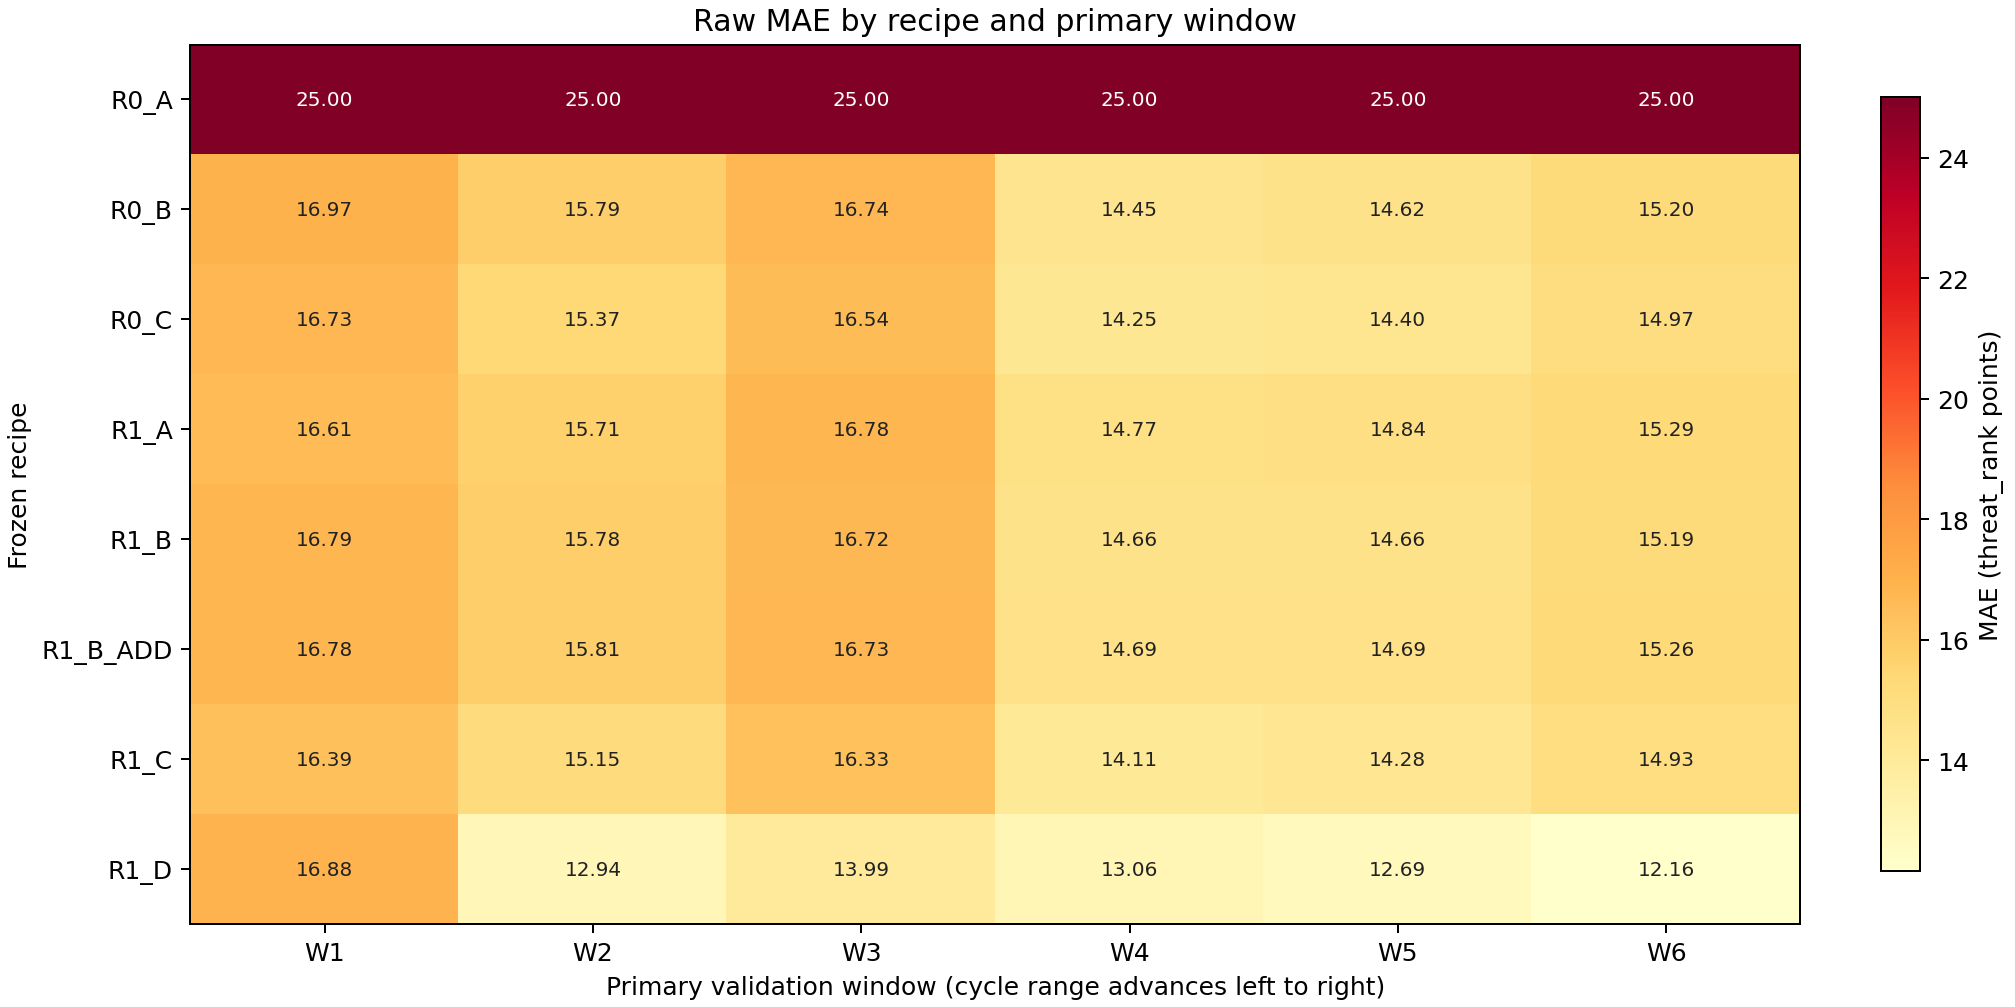

In [3]:
display(pd.DataFrame([{'recipe':m,'n':a['raw']['n'],'MAE':a['raw']['mae'],'equal-cycle MAE':a['equal_cycle_mae'],
 'RMSE':a['raw']['rmse'],'signed error':a['raw']['signed_error']} for m,a in primary.items()]).round(4))
w=pd.DataFrame([{'model':j['model'],'window':j['window'],'MAE':j['metrics']['mae']} for j in results['jobs'] if j['family']=='primary'])
display(w.pivot(index='model',columns='window',values='MAE').round(4))
display(Image(filename=str(ROOT/'reports/round1/figures/round1_primary_window_mae_heatmap.png'),alt='All eight recipes on six primary windows'))

**Interpretasi:** R0-C mengungguli R0-B pada 6/6 window dan 24/24 cycle. R1-C mengungguli R1-B serta R0-C pada seluruh 6 window / 24 cycle; gain atas lookup kecil. R1-B squared-error hanya sedikit membaik atas linear dan masih di bawah R0-C. Interaksi pada R1-B memberi gain kecil; temuan itu khusus konfigurasi squared-error ini.

R1-D menurunkan pooled primary MAE sekitar 1,80 poin dibanding R1-C, dengan 5/6 window dan 21/24 cycle membaik. W1 memburuk. Ini belum menetapkan keunggulan untuk horizon/test yang lain.

## Temporal stability — horizon 12 cycle

H12_E dan H12_L memakai ulang label primary dengan history fit berbeda, sehingga dilaporkan terpisah. Plot percycle mencakup seluruh 24 cycle validation utama.

window,H12_E,H12_L
model,,
R0_A,25.0000,24.9999
R0_B,17.0462,15.0050
R0_C,16.7388,14.7735
R1_A,16.6445,15.1500
R1_B,16.9045,15.0481
R1_B_ADD,16.9021,15.0857
R1_C,16.4321,14.6706
R1_D,17.7956,13.7004


,model,H12 pooled MAE,equal-cycle MAE
0,R0_A,25.0000,25.0000
1,R0_B,15.9405,16.0460
2,R0_C,15.6742,15.7679
3,R1_A,15.8350,15.9243
4,R1_B,15.8989,15.9908
5,R1_B_ADD,15.9182,16.0105
6,R1_C,15.4779,15.5528
7,R1_D,15.5772,15.5883


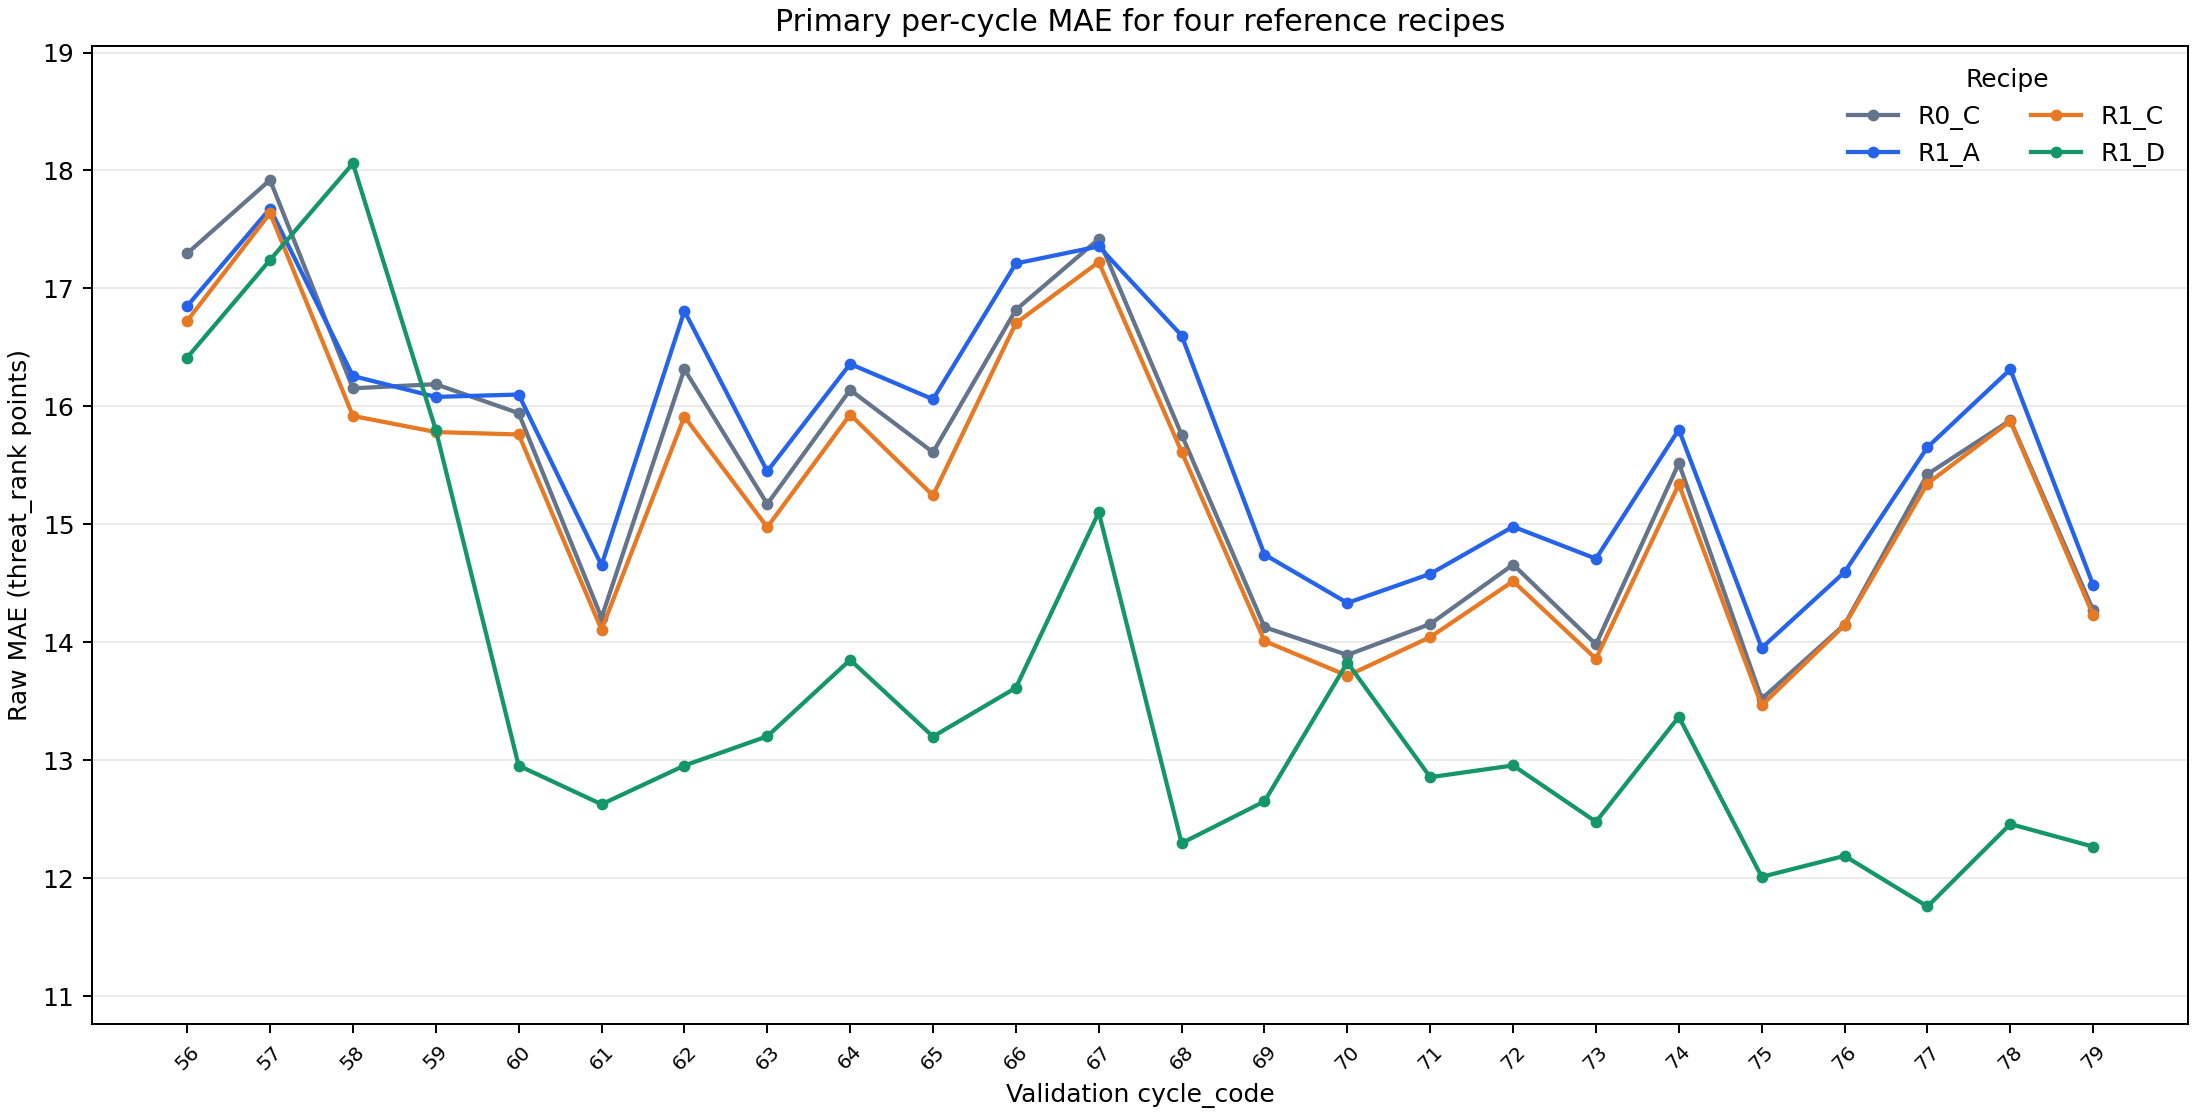

In [4]:
h=pd.DataFrame([{'model':j['model'],'window':j['window'],'MAE':j['metrics']['mae']} for j in results['jobs'] if j['family']=='secondary'])
display(h.pivot(index='model',columns='window',values='MAE').round(4))
display(pd.DataFrame([{'model':m,'H12 pooled MAE':a['raw']['mae'],'equal-cycle MAE':a['equal_cycle_mae']} for m,a in secondary.items()]).round(4))
display(Image(filename=str(ROOT/'reports/round1/figures/round1_primary_per_cycle_mae.png'),alt='Per-cycle MAE for representative frozen recipes'))

**Interpretasi:** R1-D kalah pada H12_E 17,7956 vs R1-C 16,4321. Pooled secondary R1-C 15,4779 sedikit lebih baik dari R1-D 15,5772. Feature expansion mempunyai keuntungan set-level pada primary dan horizon risk yang nyata; belum ada attribution ke satu kolom atau jaminan error test 80–91.

### Diagnostic baru tanpa recipe/fit tambahan: refresh pada record yang sama

Prediksi frozen yang sudah ada dibandingkan pada record validation identik. Parameter tetap; history dan jumlah fit rows bertambah bersamaan, sehingga bukan causal attribution recency.

In [5]:
refresh=[v for v in behavior['refresh_same_validation_rows'] if v['model'] in ['R1_C','R1_D']]
display(pd.DataFrame(refresh)[['model','older_fit_cycles','refreshed_fit_cycles','evaluation_cycles','n_same_validation_rows',
 'older_fit_mae','refreshed_fit_mae','delta_mae_refresh_minus_older']].round(4))
print('Same-fit overlap identical:',all(v['identical_predictions'] for v in behavior['same_fit_overlap_checks']))

,model,older_fit_cycles,refreshed_fit_cycles,evaluation_cycles,n_same_validation_rows,older_fit_mae,refreshed_fit_mae,delta_mae_refresh_minus_older
0,R1_C,"[47, 55]","[47, 59]","[60, 63]",6493,15.7341,15.1531,-0.5809
1,R1_D,"[47, 55]","[47, 59]","[60, 63]",6493,17.1342,12.9446,-4.1896
2,R1_C,"[47, 55]","[47, 63]","[64, 67]",7078,17.0993,16.3275,-0.7718
3,R1_D,"[47, 55]","[47, 63]","[64, 67]",7078,18.9325,13.9938,-4.9387
4,R1_C,"[47, 67]","[47, 71]","[72, 75]",7462,14.4467,14.2760,-0.1707
5,R1_D,"[47, 67]","[47, 71]","[72, 75]",7462,13.5964,12.6885,-0.9080
6,R1_C,"[47, 67]","[47, 75]","[76, 79]",8491,15.1918,14.9347,-0.2571
7,R1_D,"[47, 67]","[47, 75]","[76, 79]",8491,14.1639,12.1599,-2.0041


Same-fit overlap identical: True


**Interpretasi:** pada 60–63, update fit hingga 59 menurunkan R1-D 17,1342→12,9446, lebih besar daripada R1-C 15,7341→15,1531. Pada 64–67 pola serupa. Ini mendukung investigasi staleness/history, belum membedakan cycle effect, kategori, sample size atau fitur lain. W1 juga memburuk pada subset semua kode known/nonmissing; category novelty saja tidak cukup menjelaskan kegagalan. Diagnostic ini tidak menambah independent validation.

## Regime, target-region dan tail behavior

Signed error=prediction−actual. Regions utama 0–100/3, 100/3–200/3, 200/3–100; tails ≤ 5 / ≥ 95 adalah diagnostic tambahan, bukan tercile TP1. Denominator dilaporkan. Mean bias global kecil tidak berarti bias subgroup kecil.

,model,group,n,MAE,signed error
0,R1_C,EF0,26048,16.8175,-0.0871
1,R1_C,EF1,12540,11.6832,-0.6983
2,R1_C,region_low,12843,16.5109,14.9824
3,R1_C,region_middle,12844,13.6056,-2.7381
4,R1_C,region_high,12901,15.3298,-13.0437
5,R1_C,tail_low_le5,1928,20.7920,20.7821
6,R1_C,tail_high_ge95,1955,16.7240,-16.7240
7,R1_D,EF0,26048,14.5735,0.1672
8,R1_D,EF1,12540,10.8081,-0.4616
9,R1_D,region_low,12843,14.1209,12.0181


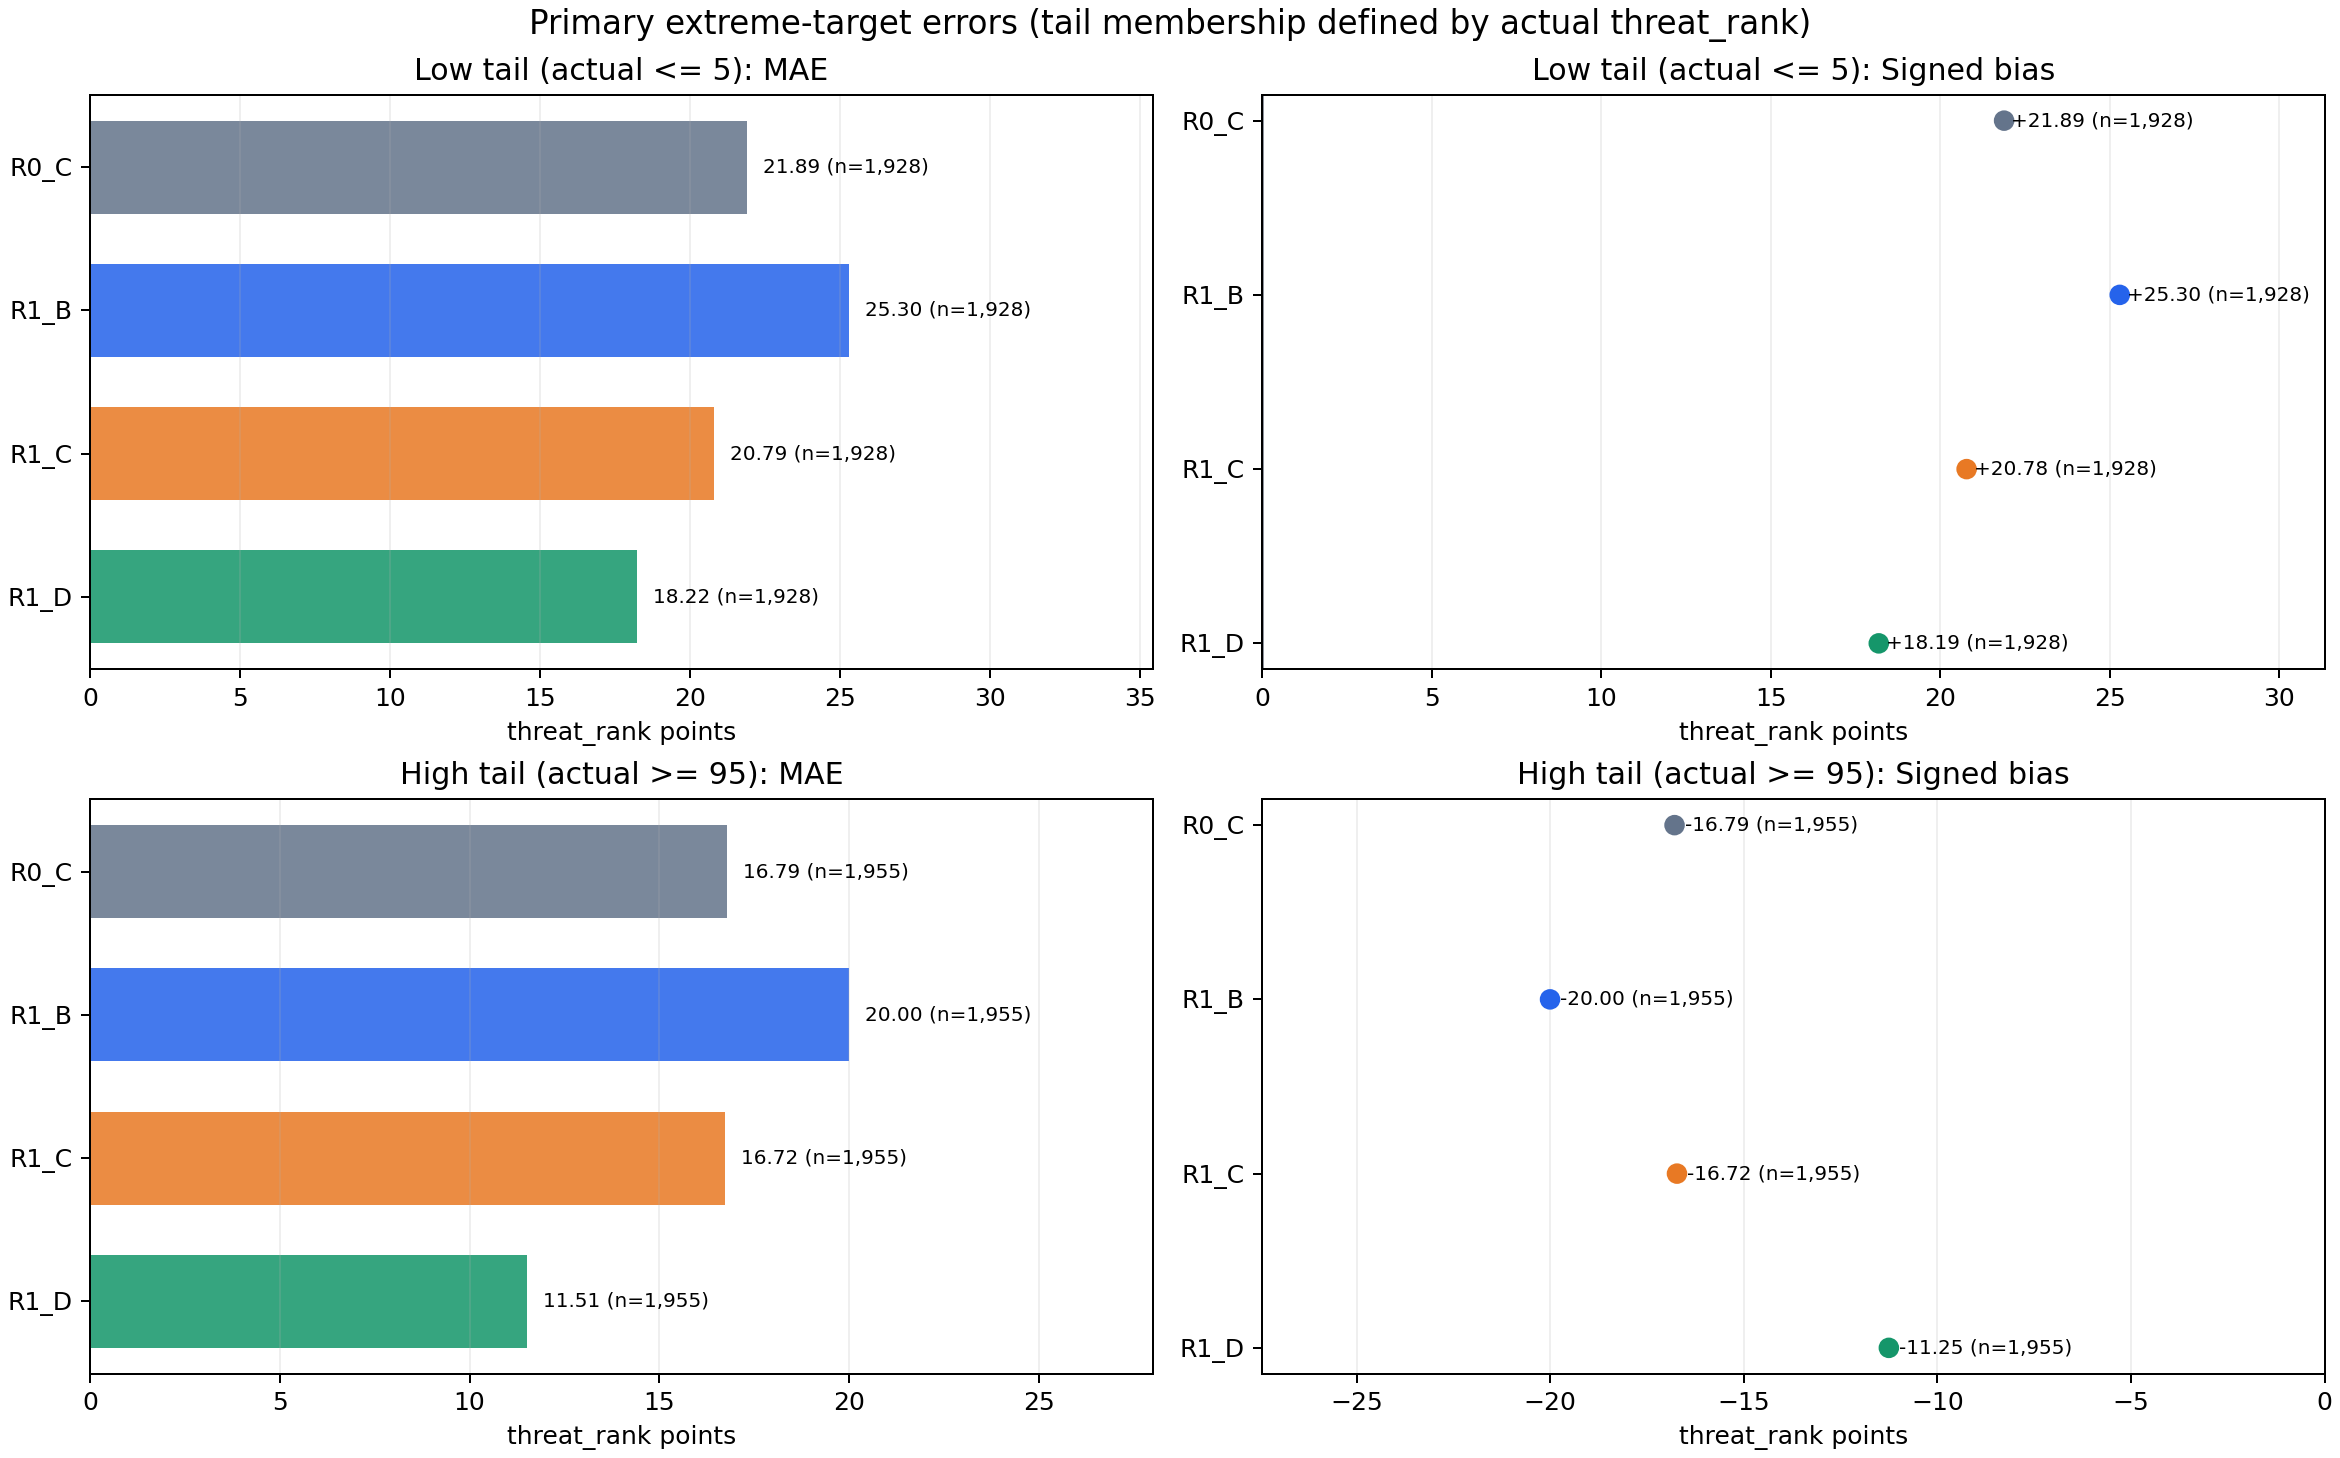

In [6]:
rows=[]
for model in ['R1_C','R1_D']:
    for group in ['EF0','EF1','region_low','region_middle','region_high','tail_low_le5','tail_high_ge95']:
        a=primary[model]['subgroups'][group]
        rows.append({'model':model,'group':group,'n':a['n'],'MAE':a['mae'],'signed error':a['signed_error']})
display(pd.DataFrame(rows).round(4))
display(Image(filename=str(ROOT/'reports/round1/figures/round1_primary_tail_mae_bias.png'),alt='Low/high tail MAE and signed errors'))

**Interpretasi:** expansion memperbaiki MAE kedua EF secara pooled, dengan gain lebih besar pada EF0. R1-D low-tail tetap overpredicted dan high-tail underpredicted meskipun global bias hampir nol. Ini prediction bias yang kini diukur pada development validation, bukan ekspektasi final/test atau pengulangan otomatis hasil TP1.

## Prediction distribution dan clipping terpisah

,model,min,median,P99,max,below0,above100,raw MAE,clipped MAE
0,R0_A,50.0000,50.0277,50.0344,50.0344,0,0,25.0000,25.0000
1,R0_B,5.4787,49.9480,87.3215,87.3215,0,0,15.5616,15.5616
2,R0_C,5.4787,49.9065,87.3215,87.3215,0,0,15.3114,15.3114
3,R1_A,8.6484,48.3342,85.6326,87.3585,0,0,15.6226,15.6226
4,R1_B,6.9479,50.0752,83.2837,83.2837,0,0,15.5710,15.5710
5,R1_B_ADD,7.3654,49.8389,83.5771,83.5771,0,0,15.6015,15.6015
6,R1_C,1.1210,49.7644,87.3200,87.9910,0,0,15.1490,15.1490
7,R1_D,-3.3077,48.2793,96.9452,103.5449,10,62,13.3498,13.3479


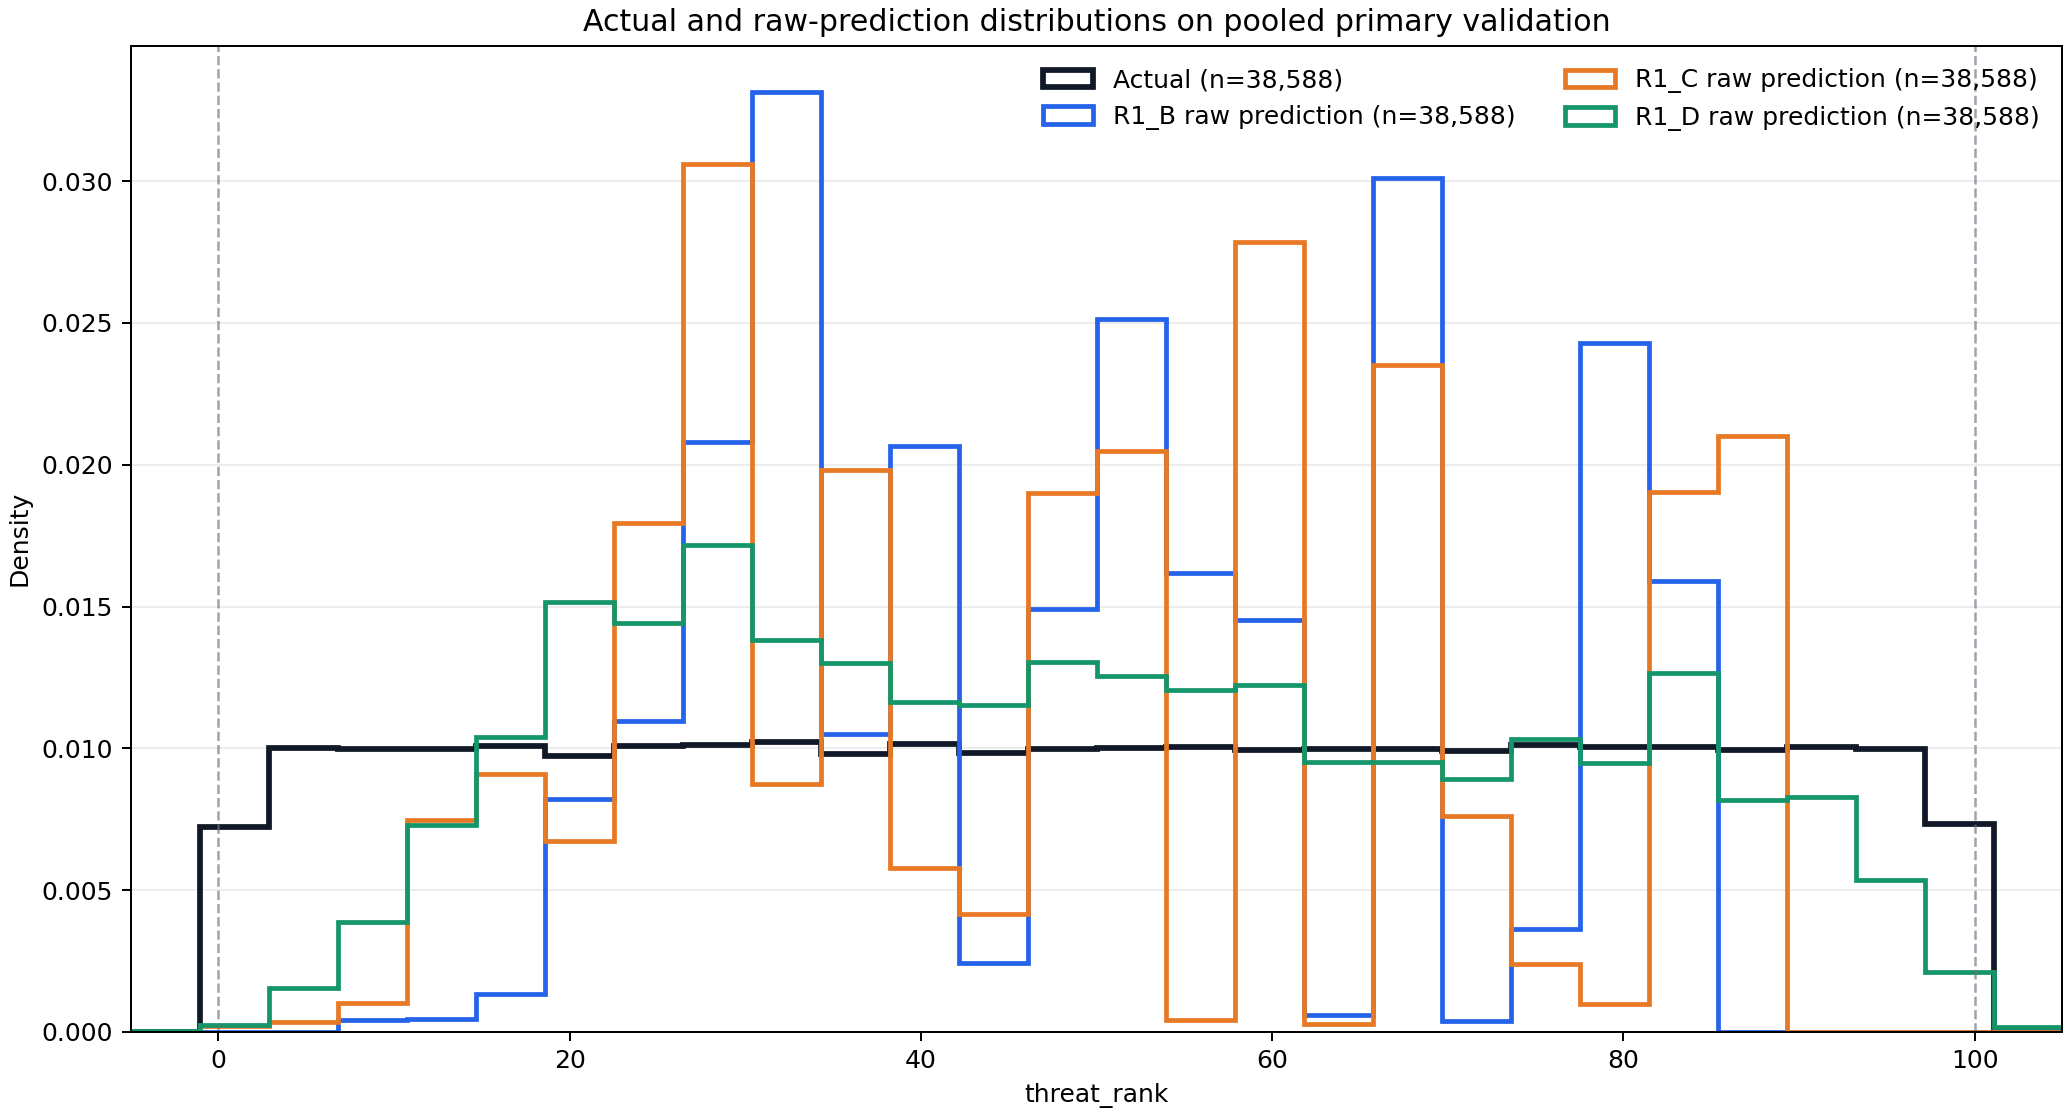

In [7]:
display(pd.DataFrame([{'model':m,'min':a['raw']['prediction_quantiles']['0'],'median':a['raw']['prediction_quantiles']['0.5'],
 'P99':a['raw']['prediction_quantiles']['0.99'],'max':a['raw']['prediction_quantiles']['1'],
 'below0':a['raw']['below_zero'],'above100':a['raw']['above_100'],'raw MAE':a['raw']['mae'],'clipped MAE':a['clipped']['mae']}
 for m,a in primary.items()]).round(4))
display(Image(filename=str(ROOT/'reports/round1/figures/round1_primary_actual_prediction_distributions.png'),alt='Aligned actual and raw predicted validation distributions'))

**Interpretasi:** R1-C predictions terkompresi dengan maksimum sekitar 87,99. R1-D memperluas distribusi dan memperbaiki tail MAE, tetapi 72 prediksi keluar 0–100. Clipping terpisah menurunkan MAE hanya sekitar 0,0019; primary tetap raw, tanpa penggantian diam-diam.

## QA, pelajaran TP1 dan keterbatasan

Semua 64 job diulang dari fit baru: prediction arrays bit-identical dan fitted audit-state hashes identik. Recompute independen MAE/bias dari actual validation errors cocok hingga floating-point error. Numeric/category preprocessing fit-only, unknown counts cocok dengan vocabulary fit. Tidak ada label test atau all-train final refit. Rincian di `VALIDATION.md` dan `ROUND1_REPRODUCIBILITY.md`.

Pelajaran conditional median dan tails dari REG-Lite B tetap relevan, sementara support target TP2 tidak mendukung penyalinan exact-score multiclass TP1. Phase16 memotivasi regime checks, tetapi tidak ada gate, model atau label tambahan TP1 yang digunakan. Fitur expanded masih mempunyai uncertainty timing/provenance; gain set-level tidak membuktikan satu fitur penyebabnya.

## Final findings — berhenti untuk review

R1-D adalah leader primary sementara, R1-C pembanding sederhana yang sedikit lebih baik pada pooled H12. Belum ada final model. Prioritas diskusi Round 2: attribution feature-group/cycle dan history sensitivity untuk kegagalan H12_E; kemudian quantile/rank-handling atau text jika disetujui. Semua masih belum dijalankan.

Pilih bersama apakah memperdalam regression atau mulai classification sebagai milestone terpisah. **Tidak ada Round 2, classification training, hyperparameter search, ensemble atau Kaggle submission.** Laporan: `reports/round1/ROUND1_FINDINGS.md`; seluruh tabel: `COMPARISON_TABLES.md`.